In [17]:
import pandas as pd
import re

#Raw RPK matrix: peptides x sample IDs

cohort_df = pd.read_csv("../preprocessing/earliest_tp_rpk_avg_value_for_cohort_techreps_071626.csv").set_index("peptide")

#sample metadata with time info
meta = pd.read_csv("../preprocessing/master_sample_metadata_060626.csv")

#import df_hbdb
hbdb_df = pd.read_csv("../preprocessing/hbdb_pass_100k_techreps_averaged_071626.csv").set_index("peptide")

#load peptide protein metadata
#protein_metadata = pd.read_csv("lassa_library_sequences_species_standardized_070726.csv")

df = pd.read_csv('../preprocessing/All_source_plates_mapped_rpk_column_names_standardized_unique_identifiers_for_duplicates_with_hbdb_plate_samples_dropped_less_100k_readcounts_071426.csv').set_index('peptide')

In [18]:
df_AG = df.filter(regex='AG', axis=1)

df_AG = df_AG + 1
df_ag_avg = df_AG.mean(axis=1)

cohort_df = cohort_df + 1
hbdb_df = hbdb_df + 1

df_AG.to_csv('df_AG.csv')

import numpy as np

mat = cohort_df.apply(pd.to_numeric, errors="coerce").fillna(0.0) #converts every column to a numeric type, if cannot be converted, fills with Nan, but then later NaN gets converted to 0.0

#log transforming before z-scoring
log_mat = np.log10(mat)

log_hbdb = np.log10(hbdb_df)

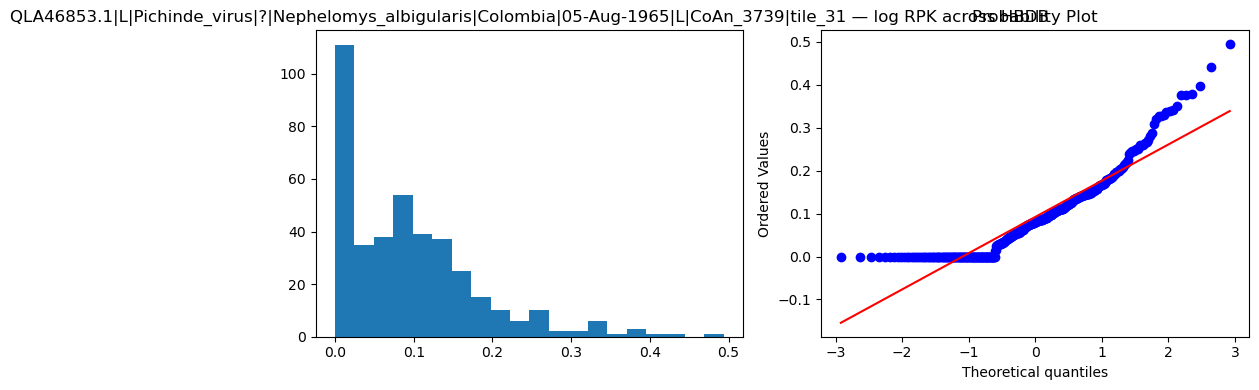

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats


peptide_id = log_mat.index[10000]  # or any specific peptide you want to spot-check
peptide_values = log_mat.loc[peptide_id].dropna()
peptide_values_log = np.log10(peptide_values + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(peptide_values_log, bins=20)
axes[0].set_title(f'{peptide_id} — log RPK across HBDB')
stats.probplot(peptide_values_log, dist='norm', plot=axes[1])
plt.tight_layout()
plt.show()

In [20]:

log_hbdb_mean = log_hbdb.mean(axis=1)

log_hbdb_std = log_hbdb.std(axis=1, ddof=1)
#to prevent inflated z-scores set threshold above a small percentile of the nonzero std
#quantile 0.01 picks a value where roughly the bottom 1% of peptides sit at or below it. so it's
#grounded by a small group of low-variance peptides rather than a single outlier. 
floor = log_hbdb_std[log_hbdb_std > 0].quantile(0.01)
log_hbdb_std = log_hbdb_std.clip(lower=floor)

#z-score using healthy controls as reference
z_mat = log_mat.sub(log_hbdb_mean, axis=0).div(log_hbdb_std, axis=0) #this aligns by peptide index
z_mat = z_mat.fillna(0.0)

z_mat.to_csv('z_score_df_after_FC_AG__SL_over_US_102226.csv')

In [21]:
# -- peptide universe
all_peps = (
    z_mat.index
    .intersection(log_hbdb.index)
)

In [22]:
# -- HBDB LOO z-scores
hbdb_cols_z = list(log_hbdb.columns)
hbdb_kept = log_hbdb.loc[all_peps, hbdb_cols_z].astype(float).values  # (n_kept, n_hbdb)
n_hbdb_s = hbdb_kept.shape[1]

z_hbdb_loo = np.full_like(hbdb_kept, np.nan, dtype=float)
for i in range(n_hbdb_s):
    idx = np.delete(np.arange(n_hbdb_s), i)

    mu = hbdb_kept[:, idx].mean(axis=1)
    sd = hbdb_kept[:, idx].std(axis=1, ddof=1)
    #use the same floor as above. not recalculating floor - it's simply a stabilization constant.
    sd = np.maximum(sd, floor)
    
    z_hbdb_loo[:, i] = (hbdb_kept[:, i] - mu) / sd

z_hbdb_loo_df = pd.DataFrame(z_hbdb_loo, index=all_peps, columns=hbdb_cols_z)

print(f"HBDB LOO z-scores computed: {n_hbdb_s} samples x {len(all_peps):,} peptides")

z_hbdb_loo_df.to_csv("z_hbdb_loo_results_after_FC_AG_102226.csv", index=True, header=True)

HBDB LOO z-scores computed: 87 samples x 90,132 peptides
